In [1]:
import pandas as pd

In [2]:
import matplotlib as plt

In [3]:
import glob
path = (glob.glob('/kaggle/input/**/housing.csv', recursive=True) + glob.glob('/content/housing.csv'))[0]
print(path)
data=pd.read_csv(path)

/content/housing.csv


In [4]:
data.head()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [5]:
data.tail()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [7]:
data.describe(include='all')

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<1H OCEAN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9136
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909,NaN
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874,NaN
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000,NaN
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000,NaN
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000,NaN
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000,NaN


In [8]:
data.isna().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

<Axes: >

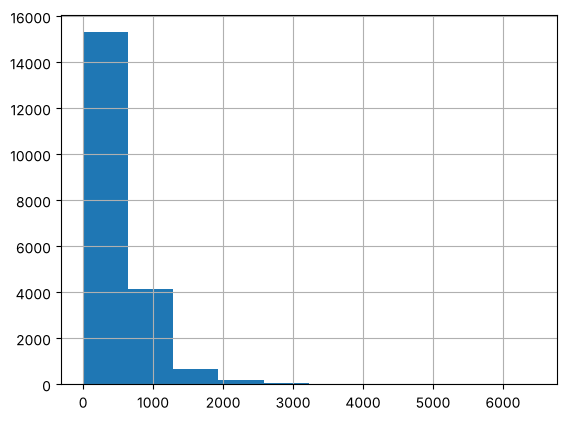

In [9]:
import matplotlib.pyplot as plt
data['total_bedrooms'].hist()

In [10]:
data['total_bedrooms']=data['total_bedrooms'].fillna(data['total_bedrooms'].median())

In [11]:
data.isna().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

In [12]:
data.duplicated().sum()

np.int64(0)

In [13]:
data['ocean_proximity'].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

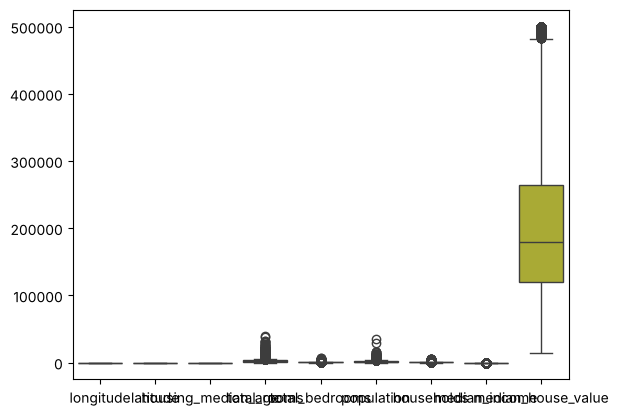

In [14]:
import seaborn as sns
box=sns.boxplot(data)

In [15]:
num_cols = data.select_dtypes(include="number").columns.drop("median_house_value")

for i in num_cols:
    q1 = data[i].quantile(0.25)
    q3 = data[i].quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr
    data[i] = data[i].clip(lower=lower_limit, upper=upper_limit)

<Axes: >

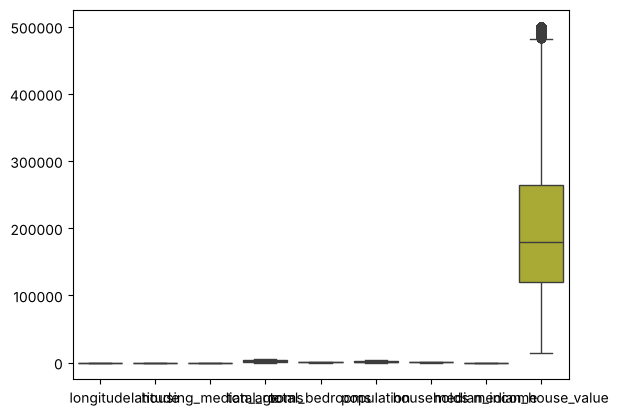

In [16]:
sns.boxplot(data)

In [17]:
data = pd.get_dummies(data, columns=['ocean_proximity'], drop_first=True, dtype=int)

In [18]:
data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.000,129.0,322.0,126.0,8.013025,452600.0,0,0,1,0
1,-122.22,37.86,21.0,5698.375,1106.0,2401.0,1092.5,8.013025,358500.0,0,0,1,0
2,-122.24,37.85,52.0,1467.000,190.0,496.0,177.0,7.257400,352100.0,0,0,1,0
3,-122.25,37.85,52.0,1274.000,235.0,558.0,219.0,5.643100,341300.0,0,0,1,0
4,-122.25,37.85,52.0,1627.000,280.0,565.0,259.0,3.846200,342200.0,0,0,1,0


In [19]:
from sklearn.model_selection import train_test_split

In [20]:
train,test=train_test_split(data,test_size=0.2,random_state=1)

In [21]:
train_y=train['median_house_value']

In [22]:
train_x=train.drop(columns=['median_house_value'])

In [23]:
test_y=test['median_house_value']
test_x=test.drop(columns=['median_house_value'])


In [24]:
train.shape

(16512, 13)

In [25]:
test.shape


(4128, 13)

In [26]:
train_x['ocean_proximity_ISLAND'].value_counts()

ocean_proximity_ISLAND
0    16507
1        5
Name: count, dtype: int64

In [27]:
from sklearn.preprocessing import StandardScaler

In [28]:
stand=StandardScaler()
train_x=stand.fit_transform(train_x)
test_x=stand.transform(test_x)

In [29]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet

In [30]:
linear_reg=LinearRegression()
model=linear_reg.fit(train_x,train_y)
Pred_y=model.predict(test_x)

In [31]:
lasso_reg=Lasso()
model=lasso_reg.fit(train_x,train_y)
Lasso_y=model.predict(test_x)

In [32]:
Ridge_reg=Ridge()
model=Ridge_reg.fit(train_x,train_y)
Ridge_y=model.predict(test_x)

In [33]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, root_mean_squared_error

In [34]:
#linear
print('Mse:'+str(mean_squared_error(test_y,Pred_y)))

print('mae :'+str(mean_absolute_error(test_y,Pred_y)))
print('r2 :'+str(r2_score(test_y,Pred_y)))

Mse:4467247973.339995
mae :49219.70379307015
r2 :0.6594282871404699


In [35]:
#lasso
print('Mse:'+str(mean_squared_error(test_y,Lasso_y)))

print('mae :'+str(mean_absolute_error(test_y,Lasso_y)))
print('r2 :'+str(r2_score(test_y,Lasso_y)))

Mse:4467216287.320374
mae :49219.35027330183
r2 :0.6594307028026496


In [36]:
#Ridge
print('Mse:'+str(mean_squared_error(test_y,Ridge_y)))

print('mae :'+str(mean_absolute_error(test_y,Ridge_y)))
print('r2 :'+str(r2_score(test_y,Ridge_y)))

Mse:4467158125.777704
mae :49218.47573888477
r2 :0.659435136891898
